# Paper 1: Henderson et al. (2020) — Quanvolutional Neural Networks on CIFAR-10
### *"Quanvolutional Neural Networks: Powering Image Recognition with Quantum Circuits"* (arXiv:1904.04767)

---

## 1. Experimental Overview (CIFAR-10: 10-Class Natural Images)
Extending the Quanvolutional framework from handwritten digits (MNIST) and clothing items (Fashion-MNIST) to **natural color images (CIFAR-10)** across all 10 classes (Airplane, Automobile, Bird, Cat, Deer, Dog, Frog, Horse, Ship, Truck).

### Methodological Highlights & Architectural Constraints:
1. **Qubit Allocation ($N_{\text{qubits}} = 4$) & Resolution Mapping:**
   - Natural images in CIFAR-10 are $32 \times 32 \times 3$.
   - To avoid exponential simulator state-space explosion (a $2 \times 2$ RGB patch would require 12 qubits with $2^{12} = 4,096$ amplitudes, requiring days of classical simulation per epoch), images are luminance-converted to single-channel grayscale and scaled to $28 \times 28$.
   - A $2 \times 2$ sliding window captures 4 local pixels $[x_0, x_1, x_2, x_3]$ mapped 1:1 to 4 qubit wires ($2^4 = 16$-dim Hilbert space).
   - Stride 2 produces an output spatial feature map of $(28 / 2) \times (28 / 2) = 14 \times 14$ with 4 quantum expectation channels ($14 \times 14 \times 4$).
2. **Three-Way Capacity-Matched Benchmark:**
   - **Model 1 (Quantum Hybrid):** Fixed random quantum circuit $\to$ 2-layer CNN.
   - **Model 2 (Classical Random Control):** Fixed random $\tanh(Wx + b)$ projection $\to$ identical 2-layer CNN.
   - **Model 3 (Classical End-to-End Baseline):** Raw $28 \times 28$ input $\to$ capacity-matched 2-layer CNN.
3. **Optimization Dynamics:** Comparative evaluation of **Adam**, **SGD with Momentum (0.9)**, and **RMSprop**.

### Step 0: Environment Setup

In [1]:
!pip install pennylane torch torchvision matplotlib scipy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


### Step 1: Simulator Device & Hardware Acceleration Setup

In [2]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

import pennylane as qml
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms

np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device} | Backend: PyTorch")

n_qubits = 4
n_layers = 1
dev = qml.device("default.qubit", wires=n_qubits)

rand_params = np.random.uniform(0.0, 2.0 * np.pi, size=(n_layers, n_qubits))
CLASSICAL_RAND_WEIGHT = np.random.randn(4, 4).astype(np.float32)
CLASSICAL_RAND_BIAS = np.random.randn(4).astype(np.float32)

Device: mps | Backend: PyTorch


### Step 2: Quantum Circuit & Feature Extraction Kernels

In [3]:
@qml.qnode(dev, interface="autograd")
def quanv_circuit_expval(inputs):
    for j in range(n_qubits):
        qml.RY(np.pi * inputs[j], wires=j)
    for layer in range(n_layers):
        for j in range(n_qubits):
            qml.RY(rand_params[layer, j], wires=j)
        qml.CNOT(wires=[0, 1])
        qml.CNOT(wires=[1, 2])
        qml.CNOT(wires=[2, 3])
        qml.CNOT(wires=[3, 0])
    return [qml.expval(qml.PauliZ(j)) for j in range(n_qubits)]

def quanvolve(image):
    h, w = image.shape[0], image.shape[1]
    out = np.zeros((h // 2, w // 2, 4), dtype=np.float32)
    for j in range(0, h, 2):
        for k in range(0, w, 2):
            patch = [float(image[j, k]), float(image[j, k+1]), float(image[j+1, k]), float(image[j+1, k+1])]
            q_results = quanv_circuit_expval(patch)
            for c in range(4):
                out[j // 2, k // 2, c] = float(q_results[c])
    return out

def classical_random_convolve(image):
    h, w = image.shape[0], image.shape[1]
    out = np.zeros((h // 2, w // 2, 4), dtype=np.float32)
    for j in range(0, h, 2):
        for k in range(0, w, 2):
            patch = np.array([image[j, k], image[j, k+1], image[j+1, k], image[j+1, k+1]], dtype=np.float32)
            out[j // 2, k // 2] = np.tanh(CLASSICAL_RAND_WEIGHT @ patch + CLASSICAL_RAND_BIAS)
    return out

### Step 3: CIFAR-10 Dataset Loading, Rescaling & Precomputed Caching

In [4]:
# Grayscale + 28x28 spatial resize
cifar_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((28, 28)),
    transforms.ToTensor()
])

train_ds = datasets.CIFAR10(root="./data_cifar", train=True, download=True)
test_ds = datasets.CIFAR10(root="./data_cifar", train=False, download=True)

N_TRAIN = 2000
N_TEST = 500

print("Transforming CIFAR-10 images to 28x28 grayscale...")
train_images = np.array([cifar_transform(train_ds.data[i]).squeeze(0).numpy() for i in range(N_TRAIN)], dtype=np.float32)
train_labels = np.array(train_ds.targets[:N_TRAIN], dtype=np.int64)
test_images = np.array([cifar_transform(test_ds.data[i]).squeeze(0).numpy() for i in range(N_TEST)], dtype=np.float32)
test_labels = np.array(test_ds.targets[:N_TEST], dtype=np.int64)

cache_dir = "./cache_cifar_quanv"
os.makedirs(cache_dir, exist_ok=True)

q_tr_path = os.path.join(cache_dir, f"q_train_{N_TRAIN}.npy")
q_te_path = os.path.join(cache_dir, f"q_test_{N_TEST}.npy")
c_tr_path = os.path.join(cache_dir, f"c_train_{N_TRAIN}.npy")
c_te_path = os.path.join(cache_dir, f"c_test_{N_TEST}.npy")

if os.path.exists(q_tr_path) and os.path.exists(q_te_path):
    print("Loading cached CIFAR-10 quantum features...")
    q_train_images = np.load(q_tr_path)
    q_test_images = np.load(q_te_path)
else:
    print(f"Precomputing quantum features for {N_TRAIN} CIFAR-10 train images...")
    t0 = time.time()
    q_train_images = np.array([quanvolve(img) for img in train_images], dtype=np.float32)
    print(f"Precomputing quantum features for {N_TEST} CIFAR-10 test images...")
    q_test_images = np.array([quanvolve(img) for img in test_images], dtype=np.float32)
    np.save(q_tr_path, q_train_images)
    np.save(q_te_path, q_test_images)

if os.path.exists(c_tr_path) and os.path.exists(c_te_path):
    print("Loading cached classical random control features...")
    c_train_images = np.load(c_tr_path)
    c_test_images = np.load(c_te_path)
else:
    print("Precomputing classical random control features...")
    c_train_images = np.array([classical_random_convolve(img) for img in train_images], dtype=np.float32)
    c_test_images = np.array([classical_random_convolve(img) for img in test_images], dtype=np.float32)
    np.save(c_tr_path, c_train_images)
    np.save(c_te_path, c_test_images)

print(f"CIFAR-10 feature maps ready. Shape: {q_train_images.shape}")

100%|██████████| 170M/170M [00:19<00:00, 8.91MB/s]   


Transforming CIFAR-10 images to 28x28 grayscale...
Precomputing quantum features for 2000 CIFAR-10 train images...
Precomputing quantum features for 500 CIFAR-10 test images...
Precomputing classical random control features...
CIFAR-10 feature maps ready. Shape: (2000, 14, 14, 4)


### Step 4: Capacity-Matched Neural Networks (10-Class Output)

In [5]:
class HybridClassifierV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=4, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

class ClassicalBaselineClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

p_hyb = sum(p.numel() for p in HybridClassifierV2().parameters())
p_base = sum(p.numel() for p in ClassicalBaselineClassifier().parameters())
print(f"Capacity Matching: Hybrid = {p_hyb} params | Classical Baseline = {p_base} params")

Capacity Matching: Hybrid = 53802 params | Classical Baseline = 53370 params


### Step 5: Training Pipeline Function

In [6]:
q_tr_tensor = torch.tensor(q_train_images.transpose(0, 3, 1, 2), dtype=torch.float32)
q_te_tensor = torch.tensor(q_test_images.transpose(0, 3, 1, 2), dtype=torch.float32)
c_tr_tensor = torch.tensor(c_train_images.transpose(0, 3, 1, 2), dtype=torch.float32)
c_te_tensor = torch.tensor(c_test_images.transpose(0, 3, 1, 2), dtype=torch.float32)
raw_tr_tensor = torch.tensor(train_images[:, np.newaxis, :, :], dtype=torch.float32)
raw_te_tensor = torch.tensor(test_images[:, np.newaxis, :, :], dtype=torch.float32)
y_tr_tensor = torch.tensor(train_labels, dtype=torch.long)
y_te_tensor = torch.tensor(test_labels, dtype=torch.long)

BATCH_SIZE = 32
q_tr_loader = DataLoader(TensorDataset(q_tr_tensor, y_tr_tensor), batch_size=BATCH_SIZE, shuffle=True)
q_te_loader = DataLoader(TensorDataset(q_te_tensor, y_te_tensor), batch_size=BATCH_SIZE, shuffle=False)
c_tr_loader = DataLoader(TensorDataset(c_tr_tensor, y_tr_tensor), batch_size=BATCH_SIZE, shuffle=True)
c_te_loader = DataLoader(TensorDataset(c_te_tensor, y_te_tensor), batch_size=BATCH_SIZE, shuffle=False)
raw_tr_loader = DataLoader(TensorDataset(raw_tr_tensor, y_tr_tensor), batch_size=BATCH_SIZE, shuffle=True)
raw_te_loader = DataLoader(TensorDataset(raw_te_tensor, y_te_tensor), batch_size=BATCH_SIZE, shuffle=False)

def train_model(model, train_loader, test_loader, epochs=30, lr=0.001, opt_name="Adam", device=device):
    model = model.to(device)
    if opt_name == "Adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    elif opt_name == "SGD_Momentum":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif opt_name == "RMSprop":
        opt = torch.optim.RMSprop(model.parameters(), lr=lr)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr)

    crit = nn.CrossEntropyLoss()
    history = {"loss": [], "train_acc": [], "test_acc": [], "gap": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct_tr, total_tr = 0.0, 0, 0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            out = model(bx)
            loss = crit(out, by)
            loss.backward()
            opt.step()
            running_loss += loss.item() * bx.size(0)
            correct_tr += (out.argmax(dim=1) == by).sum().item()
            total_tr += bx.size(0)

        model.eval()
        correct_te, total_te = 0, 0
        with torch.no_grad():
            for bx, by in test_loader:
                bx, by = bx.to(device), by.to(device)
                pred = model(bx).argmax(dim=1)
                correct_te += (pred == by).sum().item()
                total_te += bx.size(0)

        train_acc = correct_tr / total_tr
        test_acc = correct_te / total_te
        gap = train_acc - test_acc

        history["loss"].append(running_loss / total_tr)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        history["gap"].append(gap)
    return history

### Step 6: Optimizer Dynamics Benchmark on CIFAR-10

In [7]:
opt_list = ["Adam", "SGD_Momentum", "RMSprop"]
opt_results = {}
OPT_EPOCHS = 20

print(f"Evaluating Optimizer Dynamics on CIFAR-10 Quanvolutional Hybrid ({OPT_EPOCHS} epochs)...")
for opt_name in opt_list:
    torch.manual_seed(42)
    m = HybridClassifierV2()
    h = train_model(m, q_tr_loader, q_te_loader, epochs=OPT_EPOCHS, lr=0.001, opt_name=opt_name)
    opt_results[opt_name] = h
    print(f"  Optimizer: {opt_name:<14} | Final Train Acc: {h['train_acc'][-1]*100:.2f}% | Final Test Acc: {h['test_acc'][-1]*100:.2f}%")

Evaluating Optimizer Dynamics on CIFAR-10 Quanvolutional Hybrid (20 epochs)...
  Optimizer: Adam           | Final Train Acc: 64.60% | Final Test Acc: 36.20%
  Optimizer: SGD_Momentum   | Final Train Acc: 17.30% | Final Test Acc: 14.20%
  Optimizer: RMSprop        | Final Train Acc: 70.95% | Final Test Acc: 36.40%


### Step 7: Multi-Seed Benchmark across Three Models

In [8]:
EPOCHS = 30
NUM_SEEDS = 3
RUN_SEEDS = [42, 43, 44][:NUM_SEEDS]

q_accs, cr_accs, base_accs = [], [], []
q_gaps, cr_gaps, base_gaps = [], [], []
q_hist_list, cr_hist_list, base_hist_list = [], [], []

print(f"Running 3 Models on CIFAR-10 over {NUM_SEEDS} Seeds...")
for s in RUN_SEEDS:
    # 1. Quantum Hybrid
    torch.manual_seed(s)
    m_q = HybridClassifierV2()
    hq = train_model(m_q, q_tr_loader, q_te_loader, epochs=EPOCHS, lr=0.001, opt_name="Adam")
    q_accs.append(hq["test_acc"][-1])
    q_gaps.append(hq["gap"][-1])
    q_hist_list.append(hq)

    # 2. Classical Random Control
    torch.manual_seed(s)
    m_cr = HybridClassifierV2()
    hcr = train_model(m_cr, c_tr_loader, c_te_loader, epochs=EPOCHS, lr=0.001, opt_name="Adam")
    cr_accs.append(hcr["test_acc"][-1])
    cr_gaps.append(hcr["gap"][-1])
    cr_hist_list.append(hcr)

    # 3. Classical Baseline
    torch.manual_seed(s)
    m_base = ClassicalBaselineClassifier()
    hbase = train_model(m_base, raw_tr_loader, raw_te_loader, epochs=EPOCHS, lr=0.001, opt_name="Adam")
    base_accs.append(hbase["test_acc"][-1])
    base_gaps.append(hbase["gap"][-1])
    base_hist_list.append(hbase)
    print(f"  Seed {s} -> Quantum: {hq['test_acc'][-1]*100:.2f}% | Class. Rand: {hcr['test_acc'][-1]*100:.2f}% | Baseline: {hbase['test_acc'][-1]*100:.2f}%")

Running 3 Models on CIFAR-10 over 3 Seeds...
  Seed 42 -> Quantum: 34.40% | Class. Rand: 36.20% | Baseline: 35.60%
  Seed 43 -> Quantum: 33.20% | Class. Rand: 34.60% | Baseline: 35.80%
  Seed 44 -> Quantum: 36.40% | Class. Rand: 35.00% | Baseline: 39.00%


### Step 8: Summary Table and Generalization Plots

THREE-WAY CIFAR-10 EMPIRICAL BENCHMARK (3 SEEDS)
Model Architecture                   | Params   | Test Accuracy (%)    | Generalization Gap
----------------------------------------------------------------------------------------
1. Quanvolutional Hybrid (Quantum + CNN) | 53802    | 34.67 ± 1.32%       | +50.38 ± 3.18%
2. Classical Random Control (tanh + CNN) | 53802    | 35.27 ± 0.68%       | +31.73 ± 5.42%
3. Classical Baseline (Raw Pixels + CNN) | 53370    | 36.80 ± 1.56%       | +31.43 ± 3.39%


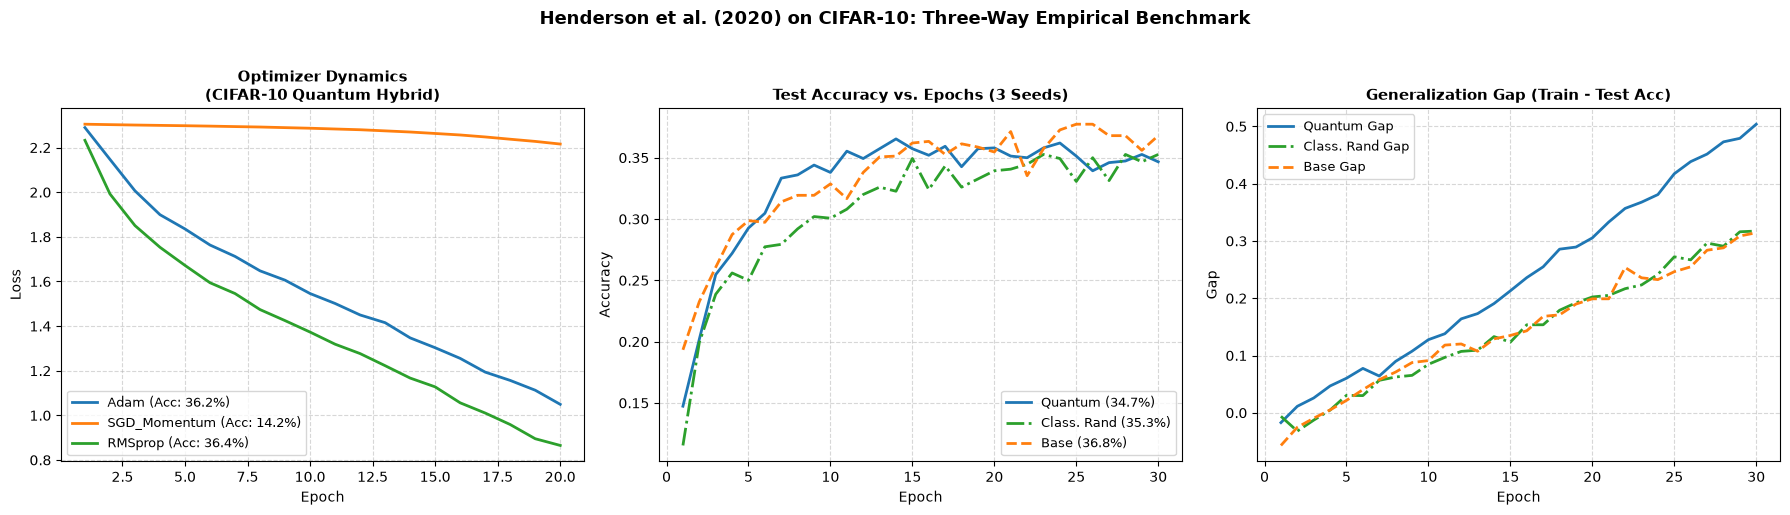

In [9]:
print("=" * 88)
print(f"THREE-WAY CIFAR-10 EMPIRICAL BENCHMARK ({NUM_SEEDS} SEEDS)")
print(f"{'Model Architecture':<36} | {'Params':<8} | {'Test Accuracy (%)':<20} | {'Generalization Gap':<16}")
print("-" * 88)
print(f"{'1. Quanvolutional Hybrid (Quantum + CNN)':<36} | {p_hyb:<8} | "
      f"{np.mean(q_accs)*100:.2f} ± {np.std(q_accs)*100:.2f}%{'':<6} | "
      f"{np.mean(q_gaps)*100:+.2f} ± {np.std(q_gaps)*100:.2f}%")
print(f"{'2. Classical Random Control (tanh + CNN)':<36} | {p_hyb:<8} | "
      f"{np.mean(cr_accs)*100:.2f} ± {np.std(cr_accs)*100:.2f}%{'':<6} | "
      f"{np.mean(cr_gaps)*100:+.2f} ± {np.std(cr_gaps)*100:.2f}%")
print(f"{'3. Classical Baseline (Raw Pixels + CNN)':<36} | {p_base:<8} | "
      f"{np.mean(base_accs)*100:.2f} ± {np.std(base_accs)*100:.2f}%{'':<6} | "
      f"{np.mean(base_gaps)*100:+.2f} ± {np.std(base_gaps)*100:.2f}%")
print("=" * 88)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_arr = np.arange(1, EPOCHS + 1)

# Panel 1: Optimizers
for opt_name, h in opt_results.items():
    axes[0].plot(np.arange(1, OPT_EPOCHS + 1), h["loss"], lw=2, label=f"{opt_name} (Acc: {h['test_acc'][-1]*100:.1f}%)")
axes[0].set_title("Optimizer Dynamics\n(CIFAR-10 Quantum Hybrid)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=10); axes[0].set_ylabel("Loss", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5); axes[0].legend(fontsize=9)

# Panel 2: Test Accuracy
axes[1].plot(epochs_arr, np.mean([h["test_acc"] for h in q_hist_list], axis=0), color="#1f77b4", lw=2, label=f"Quantum ({np.mean(q_accs)*100:.1f}%)")
axes[1].plot(epochs_arr, np.mean([h["test_acc"] for h in cr_hist_list], axis=0), color="#2ca02c", lw=2, linestyle="-.", label=f"Class. Rand ({np.mean(cr_accs)*100:.1f}%)")
axes[1].plot(epochs_arr, np.mean([h["test_acc"] for h in base_hist_list], axis=0), color="#ff7f0e", lw=2, linestyle="--", label=f"Base ({np.mean(base_accs)*100:.1f}%)")
axes[1].set_title(f"Test Accuracy vs. Epochs ({NUM_SEEDS} Seeds)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=10); axes[1].set_ylabel("Accuracy", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5); axes[1].legend(fontsize=9)

# Panel 3: Overfitting Gap
axes[2].plot(epochs_arr, np.mean([h["gap"] for h in q_hist_list], axis=0), color="#1f77b4", lw=2, label="Quantum Gap")
axes[2].plot(epochs_arr, np.mean([h["gap"] for h in cr_hist_list], axis=0), color="#2ca02c", lw=2, linestyle="-.", label="Class. Rand Gap")
axes[2].plot(epochs_arr, np.mean([h["gap"] for h in base_hist_list], axis=0), color="#ff7f0e", lw=2, linestyle="--", label="Base Gap")
axes[2].set_title("Generalization Gap (Train - Test Acc)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Epoch", fontsize=10); axes[2].set_ylabel("Gap", fontsize=10)
axes[2].grid(True, linestyle="--", alpha=0.5); axes[2].legend(fontsize=9)

plt.suptitle("Henderson et al. (2020) on CIFAR-10: Three-Way Empirical Benchmark", fontsize=13, y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()